# Data understanding, preparation and first analysis: LIDC-IDRI dataset

In [71]:
from pathlib import Path
import tqdm
from collections import Counter
import pandas as pd
import pydicom
import numpy as np
for name, typ in [("int", int), ("float", float), ("bool", bool), ("object", object)]:
    if not hasattr(np, name):
        setattr(np, name, typ)
import pylidc as pl
import matplotlib
import matplotlib.pyplot as plt
from skimage.measure import find_contours
from pylidc.utils import consensus
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import matplotlib.cm
if not hasattr(matplotlib.cm, "cmap_d"):
    matplotlib.cm.cmap_d = matplotlib.colormaps
import os
import seaborn as sns
import re
import configparser

if not hasattr(configparser, "SafeConfigParser"):
    configparser.SafeConfigParser = configparser.ConfigParser
if not hasattr(configparser.ConfigParser, "readfp"):
    configparser.ConfigParser.readfp = configparser.ConfigParser.read_file
if not hasattr(configparser, "SafeConfigParser"):
    configparser.SafeConfigParser = configparser.ConfigParser

In [72]:
# TODO: Correct the missing folders on my own data
# TODO: Check clusters with > 4 annotations manually

### 1. Data inventory and data quality summary

In this phase, we look into the data on a more structural point of view, rather then analyzing its content. It's important for understanding its hierarchy, how the files are connected with each other, and to quickly catch any unexpected values.

In [73]:
DATA_ROOT = Path(r"C:\Users\franc\Desktop\LungCT\data-analysis\raw-data")
SCAN_DIR = DATA_ROOT/"lidc_idri"
XML_DIR = DATA_ROOT/"LIDC-XML-only"
NODULE_COUNT_FILE = DATA_ROOT/"lidc-idri-nodule-counts-6-23-2015.xlsx"
DIAGNOSIS_FILE = DATA_ROOT/"tcia-diagnosis-data-2012-04-20.xls"
OUTPUT_DIR = Path(r"C:\Users\franc\Desktop\LungCT\data-analysis\processed-data")

all_files = list(DATA_ROOT.rglob("*"))
file_counts = Counter(
    path.suffix.lower()
    for path in all_files
    if path.is_file()
)
file_counts

Counter({'.dcm': 202584,
         '.xml': 1319,
         '.tmp': 49,
         '.csv': 3,
         '.xlsx': 1,
         '.xls': 1})

#### 1.1. Count patients and DICOM files

In [74]:
patient_dirs = [p for p in SCAN_DIR.iterdir() if p.is_dir()]
print("Number of patient folders:", len(patient_dirs))

for patient_dir in patient_dirs[:5]:
    dicom_files = list(patient_dir.rglob("*"))
    print(patient_dir.name, "--> ", len([f for f in dicom_files if f.is_file()]), "DICOM files")

Number of patient folders: 1010
LIDC-IDRI-0001 -->  135 DICOM files
LIDC-IDRI-0002 -->  262 DICOM files
LIDC-IDRI-0003 -->  145 DICOM files
LIDC-IDRI-0004 -->  242 DICOM files
LIDC-IDRI-0005 -->  135 DICOM files


Creating an auxiliary file which has the number of files associated to a certain pacient, to verify inconsistencies or special cases.

In [75]:
records = []
for patient_dir in patient_dirs:
    files = [f for f in patient_dir.rglob("*") if f.is_file()]
    records.append({
        "patient_folder": patient_dir.name,
        "n_dcm": sum(f.suffix.lower() == ".dcm" for f in files),
    })

file_inventory = pd.DataFrame(records)
file_inventory.head()

,patient_folder,n_dcm
0,LIDC-IDRI-0001,135
1,LIDC-IDRI-0002,262
2,LIDC-IDRI-0003,145
3,LIDC-IDRI-0004,242
4,LIDC-IDRI-0005,135


In [76]:
empty_patients = set(file_inventory.loc[file_inventory["n_dcm"] == 0, "patient_folder"])
xml_series_uids = set()
n_xml = 0
for p in XML_DIR.rglob("*.xml"):
    n_xml += 1
    with open(p, errors="ignore") as fh:
        head = fh.read(20000)
    m = re.search(r"<SeriesInstanceUid>\s*([\d.]+)\s*<", head, flags=re.I)
    if m:
        xml_series_uids.add(m.group(1))
print(f"XML files: {n_xml} | with a SeriesInstanceUid: {len(xml_series_uids)}")

patients_with_xml = {
    s.patient_id for s in pl.query(pl.Scan).all()
    if s.series_instance_uid in xml_series_uids
}
empty_with_xml    = empty_patients & patients_with_xml
empty_without_xml = empty_patients - patients_with_xml

print(f"Empty DICOM folders: {len(empty_patients)}")
print(f"Without XML annotation: {len(empty_without_xml)}")

VALID_PATIENTS = set(file_inventory.loc[file_inventory["n_dcm"] > 0, "patient_folder"])
print(f"Patients with any DICOM file: {len(VALID_PATIENTS)}")


XML files: 1319 | with a SeriesInstanceUid: 1294
Empty DICOM folders: 69
Without XML annotation: 0
Patients with any DICOM file: 941


#### 1.2. Building a DICOM metadata dataframe

In [77]:
csv_path = DATA_ROOT / "dicom_inventory.csv"

# Load existing inventory if it exists
if csv_path.exists():
    dicom_df = pd.read_csv(csv_path)
    print(f"Loaded cached inventory: {dicom_df.shape}")
else:
    records = []
    dcm_paths = list(SCAN_DIR.rglob("*.dcm"))
    for dcm_path in tqdm.tqdm(dcm_paths, desc="Reading DICOM files", unit="file"):
        try:
            ds = pydicom.dcmread(dcm_path, stop_before_pixels=True)
            records.append({
                "file_path": str(dcm_path),
                "patient_id": getattr(ds, "PatientID", None),
                "study_uid": getattr(ds, "StudyInstanceUID", None),
                "series_uid": getattr(ds, "SeriesInstanceUID", None),
                "sop_uid": getattr(ds, "SOPInstanceUID", None),
                "modality": getattr(ds, "Modality", None),
                "series_description": getattr(ds, "SeriesDescription", None),
                "slice_thickness": getattr(ds, "SliceThickness", None),
                "spacing_between_slices":  getattr(ds, "SpacingBetweenSlices", None),
                "pixel_spacing": getattr(ds, "PixelSpacing", None),
                "rows": getattr(ds, "Rows", None),
                "columns": getattr(ds, "Columns", None),
                "instance_number": getattr(ds, "InstanceNumber", None),
                "image_position_patient":  getattr(ds, "ImagePositionPatient", None),
                "image_orientation_patient": getattr(ds, "ImageOrientationPatient", None),
                "rescale_slope": getattr(ds, "RescaleSlope", None),
                "rescale_intercept": getattr(ds, "RescaleIntercept", None),
            })

        except Exception as e:
            print("Could not read:", dcm_path)
            print(e)
    dicom_df = pd.DataFrame(records)
    dicom_df.to_csv(csv_path, index=False)

C:\Users\franc\AppData\Local\Temp\ipykernel_12688\3512964781.py:5: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  dicom_df = pd.read_csv(csv_path)


Loaded cached inventory: (202584, 17)


#### 1.3. Missingness in the DICOM inventory

In [78]:
metadata_columns = [
    "patient_id", "study_uid", "series_uid", "sop_uid", "modality",
    "slice_thickness", "pixel_spacing", "rows", "columns", "instance_number"
]
available_columns = [c for c in metadata_columns if c in dicom_df.columns]
missing_summary = pd.DataFrame({
    "missing_count": dicom_df[available_columns].isna().sum(),
    "missing_percent": (dicom_df[available_columns].isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing_summary)

print("Duplicate SOP Instance UIDs:", dicom_df["sop_uid"].duplicated().sum() if "sop_uid" in dicom_df else "column unavailable")
print("Unique patient IDs:", dicom_df["patient_id"].nunique(dropna=True) if "patient_id" in dicom_df else "column unavailable")

,missing_count,missing_percent
slice_thickness,569,0.28
pixel_spacing,537,0.27
study_uid,0,0.00
patient_id,0,0.00
sop_uid,0,0.00
series_uid,0,0.00
modality,0,0.00
rows,0,0.00
columns,0,0.00
instance_number,0,0.00


Duplicate SOP Instance UIDs: 0
Unique patient IDs: 941


#### 1.4. Filtering only CT scans and verifying spatial ordering

In [79]:
def parse_two_floats(s):
    """Parse pixel_spacing / similar into a pair of floats."""
    if pd.isna(s):
        return (np.nan, np.nan)
    if isinstance(s, (list, tuple)):
        return (float(s[0]), float(s[1]))
    s = str(s).strip().strip("[]")
    parts = [p.strip() for p in s.split(",")]
    if len(parts) != 2:
        return (np.nan, np.nan)
    try:
        return (float(parts[0]), float(parts[1]))
    except ValueError:
        return (np.nan, np.nan)


ct_df = dicom_df[dicom_df["modality"] == "CT"].copy()

spacing_parsed = ct_df["pixel_spacing"].apply(parse_two_floats)
ct_df["pixel_spacing_x"] = [p[0] for p in spacing_parsed]
ct_df["pixel_spacing_y"] = [p[1] for p in spacing_parsed]

diff = (ct_df["pixel_spacing_x"] - ct_df["pixel_spacing_y"]).abs()
print(f"Non-square pixel count: {(diff > 1e-6).sum()}")

print("Top pixel spacing values (mm):")
print(ct_df["pixel_spacing_x"].value_counts().head(10))

Non-square pixel count: 0
Top pixel spacing values (mm):
pixel_spacing_x
0.703125    33305
0.781250     8797
0.625000     8730
0.664062     8688
0.742188     7861
0.585938     7720
0.664062     4359
0.585938     3412
0.820312     3348
0.546875     3294
Name: count, dtype: int64


#### 1.5. Series-level aggregation and visualization

In [80]:
series_df = (
    ct_df.groupby(["patient_id", "series_uid"])
    .agg(
        n_slices=("sop_uid", "count"),
        slice_thickness=("slice_thickness", "first"),
        spacing_between_slices=("spacing_between_slices", "first"),
        pixel_spacing_x=("pixel_spacing_x", "first"),
        pixel_spacing_y=("pixel_spacing_y", "first"),
        rows=("rows", "first"),
        columns=("columns", "first"),
        series_description=("series_description", "first"),
    )
    .reset_index()
)

print(f"CT series: {len(series_df)}")
print(f"Patients with CT: {series_df['patient_id'].nunique()}")
print("\nNumeric summary:")
print(series_df[["n_slices", "slice_thickness", "pixel_spacing_x"]].describe())

CT series: 882
Patients with CT: 874

Numeric summary:
         n_slices  slice_thickness  pixel_spacing_x
count  882.000000       882.000000       882.000000
mean   229.041950         1.931122         0.683231
std    122.198502         0.743029         0.085033
min     65.000000         0.600000         0.460938
25%    132.250000         1.250000         0.625000
50%    201.000000         2.000000         0.682617
75%    275.000000         2.500000         0.735840
max    764.000000         5.000000         0.976562


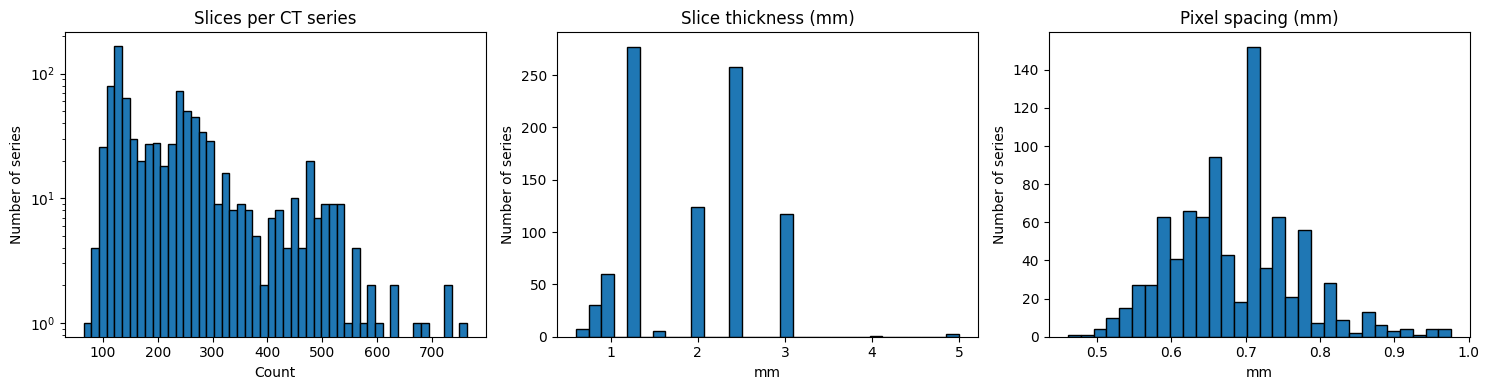

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(series_df["n_slices"], bins=50, edgecolor="black")
axes[0].set_title("Slices per CT series")
axes[0].set_xlabel("Count")
axes[0].set_ylabel("Number of series")
axes[0].set_yscale("log")

axes[1].hist(series_df["slice_thickness"].dropna(), bins=30, edgecolor="black")
axes[1].set_title("Slice thickness (mm)")
axes[1].set_xlabel("mm")
axes[1].set_ylabel("Number of series")

axes[2].hist(series_df["pixel_spacing_x"].dropna(), bins=30, edgecolor="black")
axes[2].set_title("Pixel spacing (mm)")
axes[2].set_xlabel("mm")
axes[2].set_ylabel("Number of series")

plt.tight_layout()
plt.show()

#### 1.6. Extract Z position

In [82]:
def extract_z(pos):
    if pd.isna(pos):
        return np.nan
    if isinstance(pos, str):
        parts = [p.strip() for p in pos.strip("[]").split(",")]
        try:
            return float(parts[2])
        except (IndexError, ValueError):
            return np.nan
    if isinstance(pos, (list, tuple)) and len(pos) >= 3:
        return float(pos[2])
    return np.nan


ct_df["z_position"] = ct_df["image_position_patient"].apply(extract_z)
print("NaN z_position:", ct_df["z_position"].isna().sum())

NaN z_position: 0


#### 1.7. Missing slice detection

Series checked: 882
Series with irregular spacing: 7 (0.8%)
Worst cases:
         patient_id                                         series_uid  \
881  LIDC-IDRI-1011  1.3.6.1.4.1.14519.5.2.1.6279.6001.272123398257...   
880  LIDC-IDRI-1010  1.3.6.1.4.1.14519.5.2.1.6279.6001.550599855064...   
877  LIDC-IDRI-1006  1.3.6.1.4.1.14519.5.2.1.6279.6001.397062004302...   
429  LIDC-IDRI-0514  1.3.6.1.4.1.14519.5.2.1.6279.6001.526570782606...   
866  LIDC-IDRI-0993  1.3.6.1.4.1.14519.5.2.1.6279.6001.302876782304...   
869  LIDC-IDRI-0997  1.3.6.1.4.1.14519.5.2.1.6279.6001.803987517543...   
873  LIDC-IDRI-1001  1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...   
6    LIDC-IDRI-0007  1.3.6.1.4.1.14519.5.2.1.6279.6001.272348349298...   
7    LIDC-IDRI-0008  1.3.6.1.4.1.14519.5.2.1.6279.6001.774060103415...   
8    LIDC-IDRI-0009  1.3.6.1.4.1.14519.5.2.1.6279.6001.286061375572...   

     n_slices  n_gaps  min_spacing  max_spacing   std_spacing  
881        90      33     2.500000    10.000000 

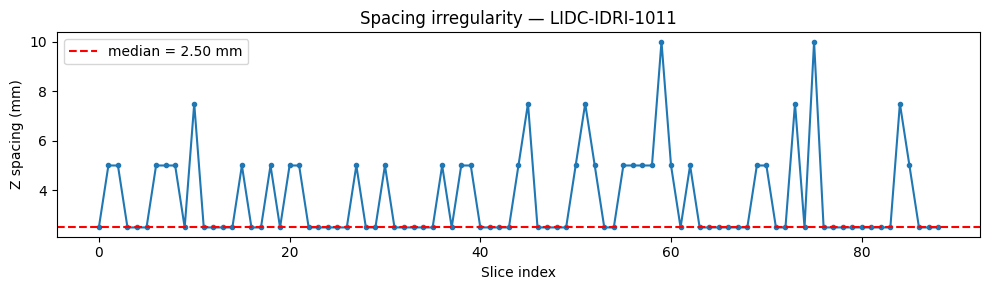

In [83]:
def check_series_regularity(positions_z):
    z = np.sort(np.asarray(positions_z, dtype=float))
    if len(z) < 2:
        return (0, np.nan, np.nan, np.nan)
    diffs = np.diff(z)
    median = np.median(np.abs(diffs))
    if median == 0:
        return (0, float(diffs.min()), float(diffs.max()), float(diffs.std()))
    gaps = int((np.abs(diffs) > 1.5 * median).sum())
    return (gaps, float(diffs.min()), float(diffs.max()), float(diffs.std()))


irregular_rows = []
for (pid, suid), grp in ct_df.dropna(subset=["z_position"]).groupby(["patient_id", "series_uid"]):
    n_gaps, dmin, dmax, dstd = check_series_regularity(grp["z_position"])
    irregular_rows.append({
        "patient_id":   pid,
        "series_uid":   suid,
        "n_slices":     len(grp),
        "n_gaps":       n_gaps,
        "min_spacing":  dmin,
        "max_spacing":  dmax,
        "std_spacing":  dstd,
    })

irregular_df = pd.DataFrame(
    irregular_rows,
    columns=["patient_id", "series_uid", "n_slices", "n_gaps", "min_spacing", "max_spacing", "std_spacing"],
)
n_irregular = int((irregular_df["n_gaps"] > 0).sum())
n_checked = len(irregular_df)
percent_irregular = 100 * n_irregular / n_checked if n_checked else 0.0
print(f"Series checked: {n_checked}")
print(f"Series with irregular spacing: {n_irregular} ({percent_irregular:.1f}%)")

if percent_irregular == 0:
    print("No CT series with valid Z positions to check.")
else:
    print("Worst cases:")
    print(irregular_df.sort_values("n_gaps", ascending=False).head(10))

    # For the worst series, plot consecutive slice spacings
    worst = irregular_df.sort_values("n_gaps", ascending=False).iloc[0]
    grp = ct_df[
        (ct_df["patient_id"] == worst["patient_id"]) &
        (ct_df["series_uid"] == worst["series_uid"])
    ].sort_values("z_position")

    zs = grp["z_position"].values
    dz = np.diff(zs)

    plt.figure(figsize=(10, 3))
    plt.plot(range(len(dz)), dz, marker="o", linestyle="-", markersize=3)
    plt.axhline(np.median(np.abs(dz)), color="red", linestyle="--",
                label=f"median = {np.median(np.abs(dz)):.2f} mm")
    plt.xlabel("Slice index")
    plt.ylabel("Z spacing (mm)")
    plt.title(f"Spacing irregularity — {worst['patient_id']}")
    plt.legend()
    plt.tight_layout()
    plt.show()

#### 1.8. Data quality summary

In [84]:
quality_summary = pd.DataFrame([
    {"metric": "Total patient folders",              "value": len(patient_dirs)},
    {"metric": "Patient folders with DICOM",         "value": len(VALID_PATIENTS)},
    {"metric": "Empty DICOM folders",                "value": len(empty_patients)},
    {"metric": "Empty folders with XML",             "value": len(empty_with_xml)},
    {"metric": "Empty folders without XML",          "value": len(empty_without_xml)},
    {"metric": "Total CT series",                    "value": len(series_df)},
    {"metric": "Series with irregular spacing",      "value": n_irregular},
    {"metric": "Median slices per series",           "value": float(series_df["n_slices"].median())},
    {"metric": "Median slice thickness (mm)",        "value": float(series_df["slice_thickness"].median())},
    {"metric": "Median pixel spacing (mm)",          "value": float(series_df["pixel_spacing_x"].median())},
])
quality_summary

,metric,value
0,Total patient folders,1010.000000
1,Patient folders with DICOM,941.000000
2,Empty DICOM folders,69.000000
3,Empty folders with XML,69.000000
4,Empty folders without XML,0.000000
5,Total CT series,882.000000
6,Series with irregular spacing,7.000000
7,Median slices per series,201.000000
8,Median slice thickness (mm),2.000000
9,Median pixel spacing (mm),0.682617


### 2. XML contour extraction

#### 2.1. Extract all annotations

In [85]:
scans = pl.query(pl.Scan).all()
ann_rows = []

for s in tqdm.tqdm(scans, desc="Parsing annotations"):
    try:
        clusters = s.cluster_annotations(verbose=False)
    except Exception as e:
        print(f"  [WARN] Clustering failed for {s.patient_id}: {e}")
        continue

    for nodule_id, cluster in enumerate(clusters):
        for k, a in enumerate(cluster):
            # Count contours and total points (for diagnostics)
            n_contours = len(a.contours) if hasattr(a, "contours") else None
            centroid = np.asarray(a.centroid, dtype=float)
            ann_rows.append({
                "patient_id":           s.patient_id,
                "nodule_id":            nodule_id,
                "scan_id":              s.id,
                "series_uid":           s.series_instance_uid,
                "annotation_idx":       k,
                "n_readers_in_cluster": len(cluster),
                "n_contours":           n_contours, # one per slice where the nodule appears
                "centroid":             centroid,
                "malignancy":           a.malignancy,
                "spiculation":          a.spiculation,
                "texture":              a.texture,
                "calcification":        a.calcification,
                "subtlety":             a.subtlety,
                "lobulation":           a.lobulation,
                "sphericity":           a.sphericity,
                "margin":               a.margin,
                "diameter":             a.diameter,
                "volume":               a.volume,
                "surface_area":         a.surface_area,
                "pixel_spacing":        s.pixel_spacing,
                "slice_spacing":        s.slice_spacing,
            })

ann_df = pd.DataFrame(ann_rows)
print(f"\nAnnotation rows:       {len(ann_df)}")
print(f"Unique patients:       {ann_df['patient_id'].nunique()}")
print(f"Unique nodule clusters: {ann_df.groupby(['patient_id', 'nodule_id']).ngroups}")
ann_df.head()

Parsing annotations: 100%|██████████| 1018/1018 [03:41<00:00,  4.60it/s]


Annotation rows:       6859
Unique patients:       875
Unique nodule clusters: 2630


,patient_id,nodule_id,scan_id,series_uid,annotation_idx,n_readers_in_cluster,n_contours,centroid,malignancy,spiculation,...,calcification,subtlety,lobulation,sphericity,margin,diameter,volume,surface_area,pixel_spacing,slice_spacing
0,LIDC-IDRI-0078,0,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,0,4,6,"[312.30982367758185, 331.9068010075567, 25.649...",3,2,...,6,4,1,4,4,19.500000,2621.82375,1135.239277,0.65,3.0
1,LIDC-IDRI-0078,0,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,1,4,6,"[309.91796875, 328.60546875, 25.41015625]",4,1,...,6,4,2,4,2,27.653662,2703.57750,1360.254889,0.65,3.0
2,LIDC-IDRI-0078,0,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,2,4,5,"[309.8829365079365, 327.9166666666667, 25.1726...",5,4,...,6,5,4,4,4,27.980216,2260.58625,1242.948800,0.65,3.0
3,LIDC-IDRI-0078,0,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,3,4,4,"[313.8805031446541, 332.5566037735849, 25.4811...",3,2,...,6,5,2,4,3,20.647094,2479.23000,1035.254928,0.65,3.0
4,LIDC-IDRI-0078,1,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,0,4,6,"[169.19642857142858, 360.8112244897959, 46.201...",3,1,...,6,5,1,3,4,20.840585,2439.30375,1124.125177,0.65,3.0


Verifying clustering issues

In [86]:
cluster_sizes = (
    ann_df
    .groupby(["patient_id", "nodule_id", "scan_id"])
    .size()
    .reset_index(name="n_annotations")
)

over_4 = cluster_sizes[cluster_sizes["n_annotations"] > 4]
print(f"Clusters with more than 4 annotations: {len(over_4)}")
print(f"Unique patients affected: {over_4['patient_id'].nunique()}")

over_4.sort_values("n_annotations", ascending=False).head(20)

Clusters with more than 4 annotations: 14
Unique patients affected: 14


,patient_id,nodule_id,scan_id,n_annotations
877,LIDC-IDRI-0340,0,342,8
944,LIDC-IDRI-0366,0,370,7
2479,LIDC-IDRI-0942,0,713,7
1061,LIDC-IDRI-0404,4,408,7
176,LIDC-IDRI-0055,0,66,6
620,LIDC-IDRI-0204,0,205,6
852,LIDC-IDRI-0332,0,334,5
706,LIDC-IDRI-0252,0,252,5
422,LIDC-IDRI-0137,2,140,5
276,LIDC-IDRI-0092,1,100,5


Temporary solution: delete problematic cases with more than 4 annotations.

In [87]:
valid_clusters = cluster_sizes[cluster_sizes["n_annotations"] <= 4]
annotations_capped = ann_df.merge(
    valid_clusters[["patient_id", "nodule_id"]],
    on=["patient_id", "nodule_id"],
    how="inner",
)

#### 2.2. Ratings distribution

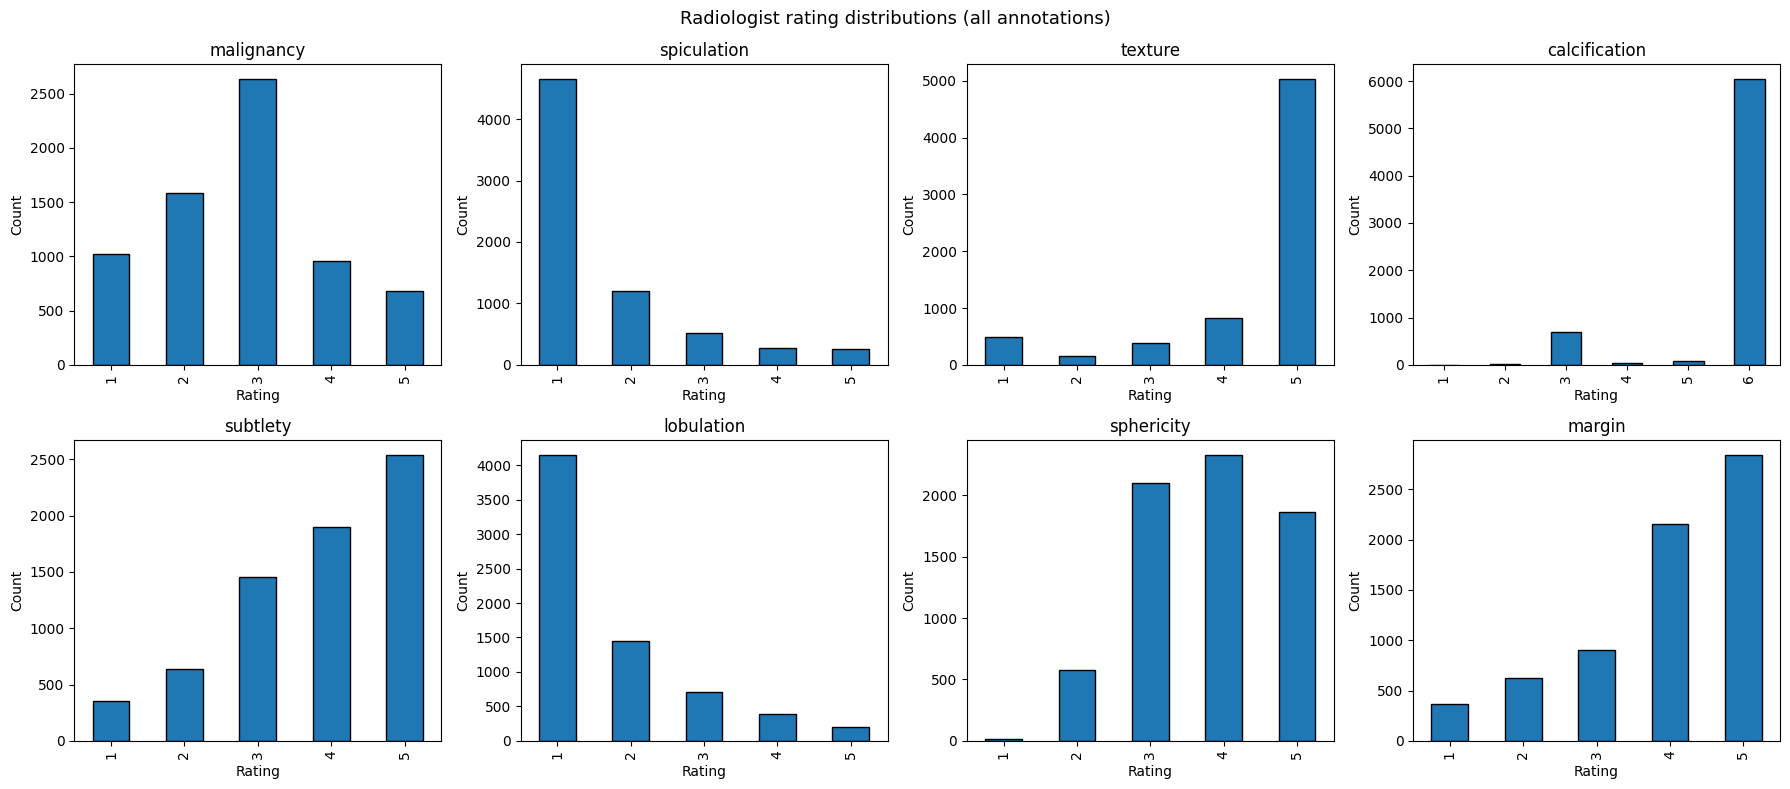

In [88]:
rating_cols = ["malignancy", "spiculation", "texture", "calcification",
               "subtlety", "lobulation", "sphericity", "margin"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), rating_cols):
    counts = annotations_capped[col].value_counts().sort_index()
    counts.plot(kind="bar", ax=ax, edgecolor="black")
    ax.set_title(col)
    ax.set_xlabel("Rating")
    ax.set_ylabel("Count")
plt.suptitle("Radiologist rating distributions (all annotations)", fontsize=13)
plt.tight_layout()
plt.show()

#### 2.3. Annotations per scan, nodules per scan and readers per nodule

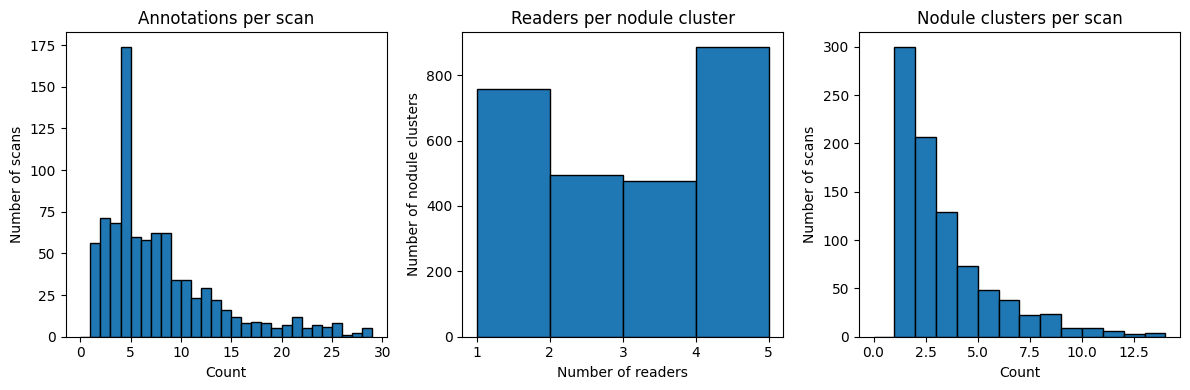

Readers-per-nodule distribution:
1    758
2    496
3    475
4    886
5      1
6      6
8     16
Name: count, dtype: int64


In [89]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

ann_per_scan = annotations_capped.groupby("scan_id").size()
axes[0].hist(ann_per_scan, bins=range(0, 30), edgecolor="black")
axes[0].set_title("Annotations per scan")
axes[0].set_xlabel("Count")
axes[0].set_ylabel("Number of scans")

n_readers = annotations_capped.groupby(["scan_id", "nodule_id"]).size()
axes[1].hist(n_readers, bins=range(1, 6), edgecolor="black")
axes[1].set_title("Readers per nodule cluster")
axes[1].set_xlabel("Number of readers")
axes[1].set_ylabel("Number of nodule clusters")

nodules_per_scan = annotations_capped.groupby("scan_id")["nodule_id"].nunique()
axes[2].hist(nodules_per_scan, bins=range(0, 15), edgecolor="black")
axes[2].set_title("Nodule clusters per scan")
axes[2].set_xlabel("Count")
axes[2].set_ylabel("Number of scans")

plt.tight_layout()
plt.show()

print("Readers-per-nodule distribution:")
print(n_readers.value_counts().sort_index())

#### 2.4. Inter-reader agreement on malignancy

       malignancy_mean  malignancy_std  malignancy_range
count      2638.000000     1880.000000       2638.000000
mean          2.691262        0.684216          0.925322
std           0.917900        0.479815          1.004406
min           1.000000        0.000000          0.000000
25%           2.000000        0.500000          0.000000
50%           2.750000        0.707107          1.000000
75%           3.000000        1.000000          2.000000
max           5.000000        2.309401          4.000000

Clusters with >=2 readers where ALL readers agree on the side of 3: 28.5%


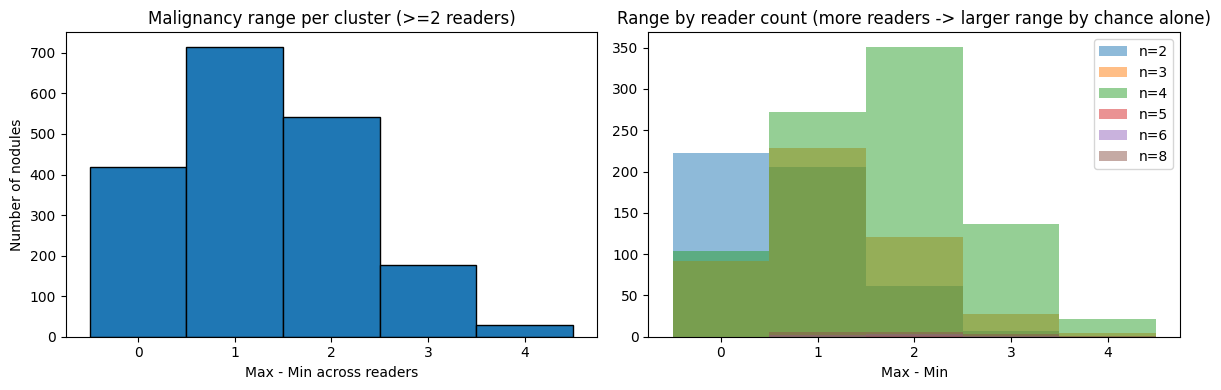

In [90]:
key = ["patient_id", "scan_id", "nodule_id"]
cluster_stats = (
    annotations_capped.groupby(key)
    .agg(
        series_uid=("series_uid", "first"),
        malignancy_mean=("malignancy", "mean"),
        malignancy_std=("malignancy", "std"),
        malignancy_min=("malignancy", "min"),
        malignancy_max=("malignancy", "max"),
        n_readers=("malignancy", "count"),
        diameter_mean=("diameter", "mean"),
        volume_mean=("volume", "mean"),
        n_contours_max=("n_contours", "max")
    )
    .reset_index()
)
cluster_stats["malignancy_range"] = cluster_stats["malignancy_max"] - cluster_stats["malignancy_min"]

# do all readers fall on the same side of "3" (benign / indeterminate / malignant)?
tmp = annotations_capped.assign(side=np.sign(annotations_capped["malignancy"] - 3))
sides = tmp.groupby(key)["side"].nunique().rename("n_sides").reset_index()
cluster_stats = cluster_stats.merge(sides, on=key)

multi = cluster_stats[cluster_stats["n_readers"] >= 2]
print(cluster_stats[["malignancy_mean", "malignancy_std", "malignancy_range"]].describe())
print(f"\nClusters with >=2 readers where ALL readers agree on the side of 3: {(multi['n_sides'] == 1).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.arange(-0.5, 5.5, 1)
axes[0].hist(multi["malignancy_range"].dropna(), bins=bins, edgecolor="black")
axes[0].set_title("Malignancy range per cluster (>=2 readers)")
axes[0].set_xlabel("Max - Min across readers")
axes[0].set_ylabel("Number of nodules")

for n in sorted(multi["n_readers"].unique()):
    subset = multi[multi["n_readers"] == n]
    axes[1].hist(subset["malignancy_range"].dropna(), bins=bins, alpha=0.5, label=f"n={n}")
axes[1].set_title("Range by reader count (more readers -> larger range by chance alone)")
axes[1].set_xlabel("Max - Min")
axes[1].legend()
plt.tight_layout()
plt.show()

#### 2.5. Visualization

Loading dicom files ... This may take a moment.


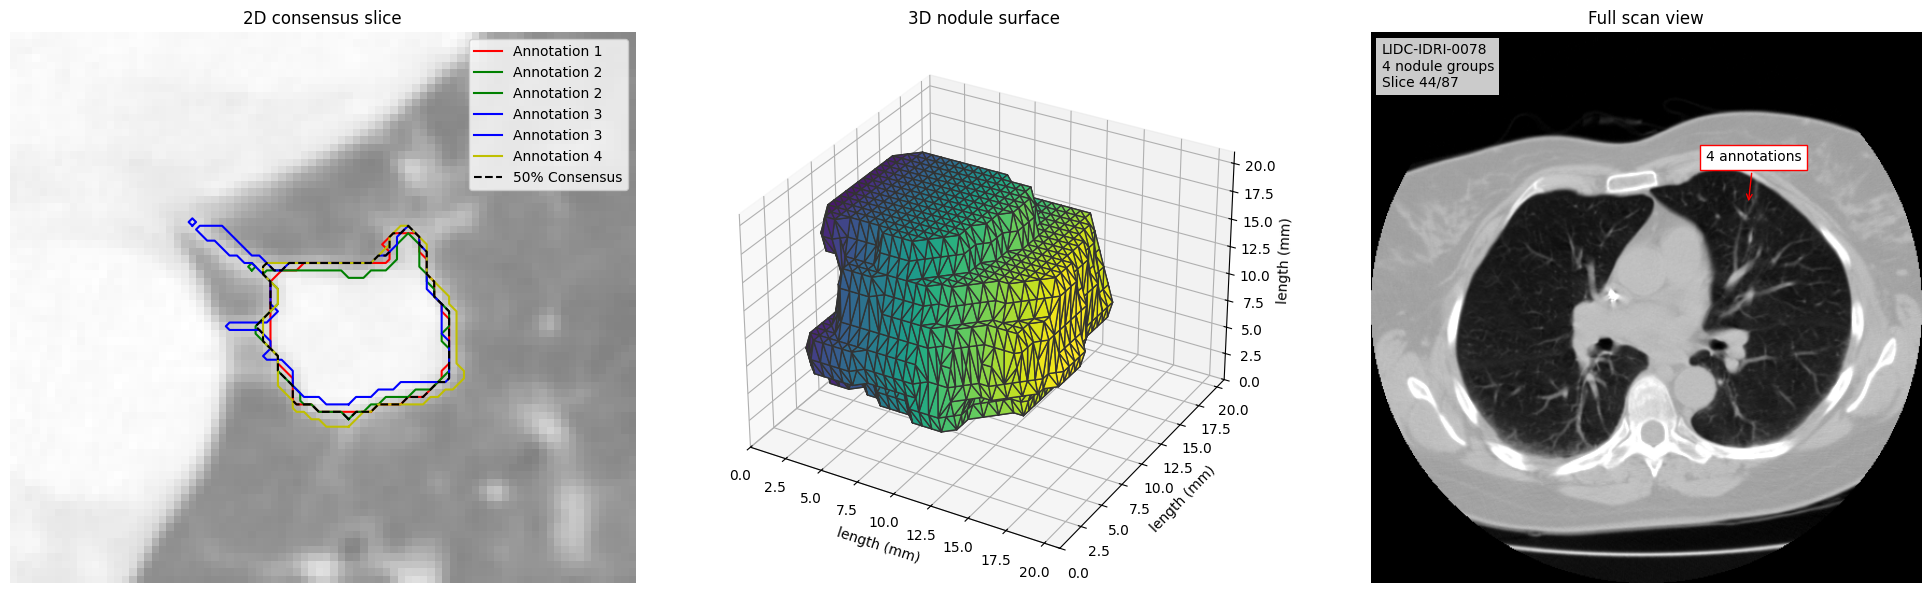

In [91]:
# Source code: https://pylidc.github.io/tuts/consensus.html
from skimage.measure import marching_cubes
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == 'LIDC-IDRI-0078').first()
vol = scan.to_volume()

# Cluster the annotations for the scan, and grab one.
nods = scan.cluster_annotations()
anns = nods[0]

# Perform a consensus consolidation and 50% agreement level.
# We pad the slices to add context for viewing.
cmask, cbbox, masks = consensus(anns, clevel=0.5,
                                pad=[(20, 20), (20, 20), (0, 0)])

# Get the central slice of the computed bounding box.
k = int(0.5 * (cbbox[2].stop - cbbox[2].start))

# Use one figure for the 2D consensus, 3D surface, and scan overview.
fig = plt.figure(figsize=(20, 6))
axes = [
    fig.add_subplot(1, 3, 1),
    fig.add_subplot(1, 3, 2, projection='3d'),
    fig.add_subplot(1, 3, 3),
]
axes[0].imshow(vol[cbbox][:, :, k], cmap=plt.cm.gray, alpha=0.5)

# Plot the annotation contours for the kth slice.
colors = ['r', 'g', 'b', 'y']
for j in range(len(masks)):
    for c in find_contours(masks[j][:, :, k].astype(float), 0.5):
        label = "Annotation %d" % (j + 1)
        axes[0].plot(c[:, 1], c[:, 0], colors[j], label=label)

# Plot the 50% consensus contour for the kth slice.
for c in find_contours(cmask[:, :, k].astype(float), 0.5):
    axes[0].plot(c[:, 1], c[:, 0], '--k', label='50% Consensus')

axes[0].set_title('2D consensus slice')
axes[0].axis('off')
axes[0].legend()

# Build the 3D mesh for the same annotation shown in the 2D panel.
ann = anns[0]
mesh_mask = ann.boolean_mask(pad=[(1, 1), (1, 1), (1, 1)])
rij = ann.scan.pixel_spacing
rk = ann.scan.slice_spacing
verts, faces, _, _ = marching_cubes(
    mesh_mask.astype(np.float32),
    0.5,
    spacing=(rij, rij, rk),
    step_size=1,
)
face_colors = plt.get_cmap('viridis')(
    np.linspace(0, 1, faces.shape[0])
)
mesh = Poly3DCollection(
    verts[faces],
    edgecolor='0.2',
    facecolors=face_colors,
)
axes[1].add_collection3d(mesh)

axis_limit = int(np.round(max(ann.bbox_dims(pad=[(1, 1), (1, 1), (1, 1)]))))
axes[1].set_xlim(0, axis_limit)
axes[1].set_ylim(0, axis_limit)
axes[1].set_zlim(0, axis_limit)
axes[1].set_xlabel('length (mm)')
axes[1].set_ylabel('length (mm)')
axes[1].set_zlabel('length (mm)')
axes[1].set_title('3D nodule surface')

# Static scan overview matching the middle-slice view in scan.visualize.
scan_slice = vol.shape[2] // 2
axes[2].imshow(vol[:, :, scan_slice], cmap=plt.cm.gray, vmin=-1000, vmax=400)
scan_z = scan.slice_zvals[scan_slice]
for group in nods:
    center = np.mean([annotation.centroid for annotation in group], axis=0)
    center_slice = int(round(center[2]))
    center_z = scan.slice_zvals[center_slice]
    if abs(scan_z - center_z) > 3 * scan.slice_spacing:
        continue
    radius = np.mean([annotation.diameter / 2 for annotation in group])
    axes[2].annotate(
        f'{len(group)} annotations',
        xy=(center[1] - radius, center[0] - radius),
        xytext=(center[1] - 50, center[0] - 50),
        bbox=dict(fc='w', ec='r'),
        arrowprops=dict(arrowstyle='->', edgecolor='r'),
    )
axes[2].text(
    0.02, 0.98,
    f'{scan.patient_id}\n{len(nods)} nodule groups\nSlice {scan_slice + 1}/{vol.shape[2]}',
    transform=axes[2].transAxes,
    va='top',
    bbox=dict(fc='w', ec='none', alpha=0.8),
)
axes[2].set_title('Full scan view')
axes[2].axis('off')

plt.tight_layout()
plt.show()

#### 2.6. Mean malignancy distribution analysis

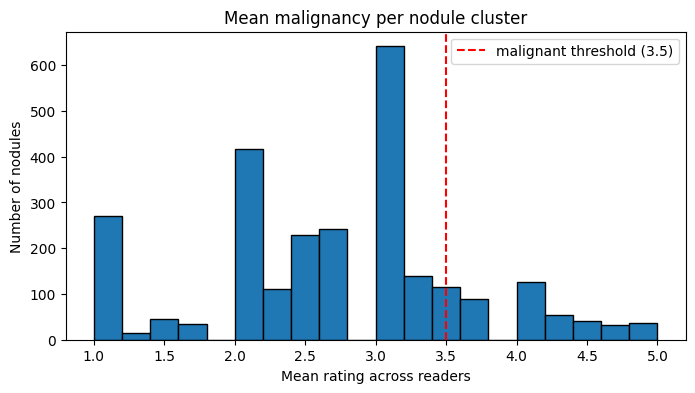

Benign (<3.5):     2143
Malignant (>=3.5): 495


In [92]:
plt.figure(figsize=(8, 4))
plt.hist(cluster_stats["malignancy_mean"], bins=20, edgecolor="black")
plt.title("Mean malignancy per nodule cluster")
plt.xlabel("Mean rating across readers")
plt.ylabel("Number of nodules")
plt.axvline(3.5, color="red", linestyle="--", label="malignant threshold (3.5)")
plt.legend()
plt.show()

malignant = (cluster_stats["malignancy_mean"] >= 3.5).sum()
benign = (cluster_stats["malignancy_mean"] < 3.5).sum()
print(f"Benign (<3.5):     {benign}")
print(f"Malignant (>=3.5): {malignant}")

Final cross checking with nodule count Excel file

In [93]:
official = pd.read_excel(DATA_ROOT/"lidc-idri-nodule-counts-6-23-2015.xlsx")

# Find the patient ID column (name varies)
id_col = [c for c in official.columns
            if "id" in c.lower() or "patient" in c.lower()][0]

official_counts = official.groupby(id_col).size().reset_index(name="official_nodules")
official_counts[id_col] = official_counts[id_col].astype(str)

pylidc_counts = (
    annotations_capped.groupby("patient_id")["nodule_id"].nunique()
    .reset_index(name="pylidc_nodules")
)

merged = official_counts.merge(
    pylidc_counts,
    left_on=id_col, right_on="patient_id", how="outer"
)
merged["diff"] = merged["pylidc_nodules"] - merged["official_nodules"]

print("Patients with largest discrepancies:")
print(merged.reindex(merged["diff"].abs().sort_values(ascending=False).index).head(10))

Patients with largest discrepancies:
     TCIA Patent ID  official_nodules      patient_id  pylidc_nodules  diff
581  LIDC-IDRI-0583                 1  LIDC-IDRI-0583            23.0  22.0
683  LIDC-IDRI-0686                 1  LIDC-IDRI-0686            21.0  20.0
852  LIDC-IDRI-0855                 1  LIDC-IDRI-0855            16.0  15.0
128  LIDC-IDRI-0129                 1  LIDC-IDRI-0129            15.0  14.0
48   LIDC-IDRI-0049                 1  LIDC-IDRI-0049            15.0  14.0
123  LIDC-IDRI-0124                 1  LIDC-IDRI-0124            15.0  14.0
739  LIDC-IDRI-0742                 1  LIDC-IDRI-0742            14.0  13.0
855  LIDC-IDRI-0858                 1  LIDC-IDRI-0858            13.0  12.0
803  LIDC-IDRI-0806                 1  LIDC-IDRI-0806            13.0  12.0
396  LIDC-IDRI-0398                 1  LIDC-IDRI-0398            13.0  12.0


This is somewhat expected. Pylidc clusters all annotations, including small and non-nodule marks. However, let's only use annotated and ranked nodules for further classification.

In [94]:
clusters_with_ratings = (
    annotations_capped
    .groupby(["patient_id", "nodule_id"])["malignancy"]
    .apply(lambda x: x.notna().any())
    .reset_index(name="has_ratings")
)

valid_clusters = clusters_with_ratings[clusters_with_ratings["has_ratings"]]
ann_df_filtered = annotations_capped.merge(
    valid_clusters[["patient_id", "nodule_id"]],
    on=["patient_id", "nodule_id"]
)

#### 2.7. Annotations dataset

In [95]:
ann_csv = OUTPUT_DIR / "annotations_all.csv"
cluster_csv = OUTPUT_DIR / "clusters_summary.csv"

ann_df_filtered.to_csv(ann_csv, index=False)
cluster_stats.to_csv(cluster_csv, index=False)

print(f"Saved: {ann_csv}")
print(f"Saved: {cluster_csv}")

Saved: C:\Users\franc\Desktop\LungCT\data-analysis\processed-data\annotations_all.csv
Saved: C:\Users\franc\Desktop\LungCT\data-analysis\processed-data\clusters_summary.csv


#### 2.8. Correlation between malignancy and other features

C:\Users\franc\AppData\Local\Temp\ipykernel_12688\2299236520.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


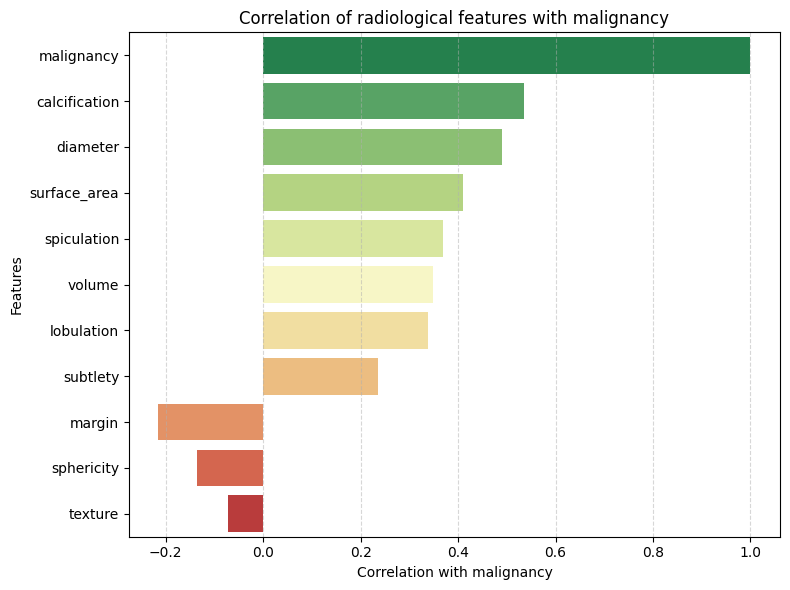

In [96]:
# Calculate Pearson Correlation
df = pd.read_csv(OUTPUT_DIR/"annotations_all.csv")
df = df.drop(columns=["nodule_id", "patient_id", "series_uid", "n_readers_in_cluster", "scan_id", "annotation_idx", "n_contours", "centroid",
                      "pixel_spacing", "slice_spacing"])
corr = df.corr()["malignancy"]
# Sort by absolute correlation
corr_sorted = corr.reindex(corr.abs().sort_values(ascending=False).index)

# Plot
plt.figure(figsize=(8, 6))
sns.barplot(
    x=corr_sorted.values,
    y=corr_sorted.index,
    palette=sns.color_palette("RdYlGn_r", n_colors=len(corr_sorted))
)
plt.xlabel("Correlation with malignancy")
plt.ylabel("Features")
plt.title("Correlation of radiological features with malignancy")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 3. Region of interest mask generation

In [97]:
nodules_3d = OUTPUT_DIR / "reconstructed_3d"
os.makedirs(nodules_3d, exist_ok=True)

PAD = 10  # voxels of context around the nodule
ZPAD = 2  # slice-axis padding
scans = pl.query(pl.Scan).all()
skipped_scans = []
saved_nodules = 0

for scan in scans:
    pid = scan.patient_id

    # Group the (up to 4) radiologists' annotations that refer to the same nodule
    nodules = scan.cluster_annotations(verbose=False)

    todo = []
    for n_idx, anns in enumerate(nodules):
        path = os.path.join(nodules_3d, f"{pid}_nodule{n_idx:02d}.npz")
        if not os.path.exists(path):
            todo.append((n_idx, anns, path))
    if not todo:
        continue

    print(f"Processing {pid}: {len(todo)} nodule(s) remaining")
    try:
        vol = scan.to_volume(verbose=False)  # convert a CT scan to a 3D NumPy array
    except OSError as exc:
        skipped_scans.append(pid)
        print(f"  Skipping {pid}: {exc}")
        continue

    for n_idx, anns, path in todo:
        cmask, cbbox, masks = consensus(
            anns, clevel=0.5, pad=[(PAD, PAD), (PAD, PAD), (ZPAD, ZPAD)]
        )

        # clip the padded box to the volume, and crop the mask the same way
        img_sl, msk_sl = [], []
        for s, size in zip(cbbox, vol.shape):
            lo, hi = max(s.start, 0), min(s.stop, size)
            img_sl.append(slice(lo, hi))
            msk_sl.append(slice(lo - s.start, hi - s.start))

        roi_img = vol[tuple(img_sl)]
        roi_mask = cmask[tuple(msk_sl)]
        assert roi_img.shape == roi_mask.shape
        roi_masked = np.where(roi_mask, roi_img, -1000)

        np.savez_compressed(
            path,
            image=roi_img.astype(np.int16),
            mask=roi_mask,
            masked_image=roi_masked.astype(np.int16),
            spacing=np.array([scan.pixel_spacing, scan.pixel_spacing, scan.slice_spacing]),
            n_annotators=len(anns),
            malignancy=np.mean([a.malignancy for a in anns]),
        )
        saved_nodules += 1

Processing LIDC-IDRI-0068: 6 nodule(s) remaining
  Skipping LIDC-IDRI-0068: Couldn't find DICOM files for Scan(id=79,patient_id=LIDC-IDRI-0068).
Processing LIDC-IDRI-0072: 1 nodule(s) remaining
  Skipping LIDC-IDRI-0072: Couldn't find DICOM files for Scan(id=82,patient_id=LIDC-IDRI-0072).
Processing LIDC-IDRI-0088: 3 nodule(s) remaining
  Skipping LIDC-IDRI-0088: Couldn't find DICOM files for Scan(id=96,patient_id=LIDC-IDRI-0088).
Processing LIDC-IDRI-0090: 1 nodule(s) remaining
  Skipping LIDC-IDRI-0090: Couldn't find DICOM files for Scan(id=98,patient_id=LIDC-IDRI-0090).
Processing LIDC-IDRI-0118: 6 nodule(s) remaining
  Skipping LIDC-IDRI-0118: Couldn't find DICOM files for Scan(id=123,patient_id=LIDC-IDRI-0118).
Processing LIDC-IDRI-0124: 15 nodule(s) remaining
  Skipping LIDC-IDRI-0124: Couldn't find DICOM files for Scan(id=129,patient_id=LIDC-IDRI-0124).
Processing LIDC-IDRI-0135: 6 nodule(s) remaining
  Skipping LIDC-IDRI-0135: Couldn't find DICOM files for Scan(id=139,patient_i

### 4. Exploratory Data Analysis

#### 4.1. Quick diagnosis - usable for classification or not?

In [116]:
df = pd.read_csv("processed-data/annotations_all.csv")

Readers disagree by >= 2 points

In [117]:
cluster_mal = (
    ann_df.groupby(["patient_id", "nodule_id"])["malignancy"]
    .agg(["min", "max", "mean", "std", "count"])
    .reset_index()
    .rename(columns={
        "min": "mal_min",
        "max": "mal_max",
        "mean": "mal_mean",
        "std": "mal_std",
        "count": "n_readers",
    })
)
cluster_mal["mal_range"] = cluster_mal["mal_max"] - cluster_mal["mal_min"]
cluster_mal["disagreement_2plus"] = cluster_mal["mal_range"] >= 2

print(f"Total clusters: {len(cluster_mal)}")
print(f"Clusters with >=2 points disagreement: {cluster_mal['disagreement_2plus'].sum()} "
      f"({100 * cluster_mal['disagreement_2plus'].mean():.1f}%)")

Total clusters: 2630
Clusters with >=2 points disagreement: 754 (28.7%)


Mean malignancy between 3.0 and 3.5

In [118]:
borderline = cluster_mal[
    cluster_mal["mal_mean"].between(3.0, 3.5, inclusive="left")
].copy()

print(f"Total clusters: {len(cluster_mal)}")
print(f"Borderline clusters (3.0-3.5): {len(borderline)} "
      f"({100 * len(borderline) / len(cluster_mal):.1f}%)")

Total clusters: 2630
Borderline clusters (3.0-3.5): 779 (29.6%)


Single-reader annotation on a small nodule

In [120]:
small_single_reader = df[(df["n_readers_in_cluster"] == 1) & (df["volume"] < 100)]
print(f"Single-reader clusters in small nodules: {len(small_single_reader)}")

Single-reader clusters in small nodules: 542


#### 4.2. Nodule diameter analysis

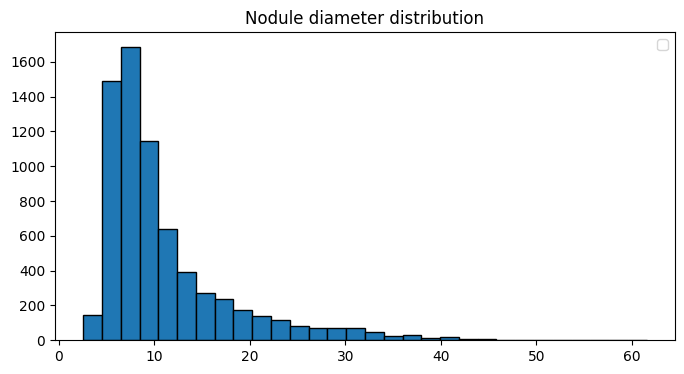

In [122]:
plt.figure(figsize=(8, 4))
plt.hist(df["diameter"], bins=30, edgecolor="black")
plt.title("Nodule diameter distribution")
plt.legend()
plt.show()

#### 4.3. Nodule distribution on lungs

#### 4.4. Average pixel spacing and slice spacing

#### 4.5 Number of slices per nodules

### 5. Final dataset

Basically, add the path to the nodule's ROI 3D reconstruction to the annotations_all.csv file.


In [100]:
annotations_csv = OUTPUT_DIR / "annotations_all.csv"
reconstruction_dir = OUTPUT_DIR / "reconstructed_3d"
annotations_df = pd.read_csv(annotations_csv)

reconstruction_paths = [
    reconstruction_dir / f"{patient_id}_nodule{int(nodule_id):02d}.npz"
    for patient_id, nodule_id in zip(
        annotations_df["patient_id"], annotations_df["nodule_id"]
    )
]
annotations_df["3d_file_path"] = [
    f"./processed-data/{path.relative_to(OUTPUT_DIR).as_posix()}"
    if path.is_file() else pd.NA
    for path in reconstruction_paths
]

annotations_df.to_csv(annotations_csv, index=False)
annotations_df.head()

,patient_id,nodule_id,scan_id,series_uid,annotation_idx,n_readers_in_cluster,n_contours,centroid,malignancy,spiculation,...,subtlety,lobulation,sphericity,margin,diameter,volume,surface_area,pixel_spacing,slice_spacing,3d_file_path
0,LIDC-IDRI-0078,0,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,0,4,6,[312.30982368 331.90680101 25.64987406],3,2,...,4,1,4,4,19.500000,2621.82375,1135.239277,0.65,3.0,./processed-data/reconstructed_3d/LIDC-IDRI-00...
1,LIDC-IDRI-0078,0,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,1,4,6,[309.91796875 328.60546875 25.41015625],4,1,...,4,2,4,2,27.653662,2703.57750,1360.254889,0.65,3.0,./processed-data/reconstructed_3d/LIDC-IDRI-00...
2,LIDC-IDRI-0078,0,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,2,4,5,[309.88293651 327.91666667 25.17261905],5,4,...,5,4,4,4,27.980216,2260.58625,1242.948800,0.65,3.0,./processed-data/reconstructed_3d/LIDC-IDRI-00...
3,LIDC-IDRI-0078,0,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,3,4,4,[313.88050314 332.55660377 25.48113208],3,2,...,5,2,4,3,20.647094,2479.23000,1035.254928,0.65,3.0,./processed-data/reconstructed_3d/LIDC-IDRI-00...
4,LIDC-IDRI-0078,1,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.303494235102...,0,4,6,[169.19642857 360.81122449 46.20153061],3,1,...,5,1,3,4,20.840585,2439.30375,1124.125177,0.65,3.0,./processed-data/reconstructed_3d/LIDC-IDRI-00...
